# 02 · EMT-TF Expression — Choudhury et al. 2022 (Meningioma, 10x)

The EMT-TF readout is **unconditional** — produced regardless of the gate outcome. Gate 1 was a **NO-GO** (per-patient archipelago; §1 notebook 01), so no trajectory is fit and this is the *last* notebook, numbered **02** (§6 renumbering: Gate 1 NO-GO → 01 + 02). We read the malignant cells from `processed.h5ad` and overlay the most informative EMT transcription factors on the (best-attempt) manifold, gated on detectable expression. No pseudotime is available or claimed.

In [1]:
import os, sys, glob
os.environ['R_HOME'] = sys.exec_prefix + '/lib/R/'
import numpy as np, pandas as pd
import scanpy as sc
import matplotlib.pyplot as plt
sc.settings.verbosity = 1
SEED = 1; np.random.seed(SEED)

In [2]:
name = os.path.basename(os.getcwd())
cat  = os.path.basename(os.path.dirname(os.getcwd()))
pth  = os.path.join(*([os.pardir]*6))
pth_data = os.path.join(pth, 'data')
pth_out = os.path.join(pth_data, 'cancer', 'vertebrate', 'CCCA', 'Claude', cat, name)
pth_fig = os.path.join(pth, 'figures', 'cancer', 'vertebrate', 'CCCA', 'Claude', cat, name)
os.makedirs(pth_fig, exist_ok=True)

In [3]:
# read the processed malignant manifold (§6: expression reads processed.h5ad)
adata = sc.read_h5ad(os.path.join(pth_out, 'processed.h5ad'))
print('cells:', adata.shape[0], '| samples:', adata.obs['sample'].nunique(),
      '| patients:', adata.obs['patient'].nunique())
adata

cells: 37049 | samples: 7 | patients: 5


AnnData object with n_obs × n_vars = 37049 × 25139
    obs: 'sample', 'patient', 'cell_type', 'cell_subtype', 'complexity', 'umap1', 'umap2', 'g1s_score', 'g2m_score', 'cell_cycle_phase', 'mp_top_score', 'mp_top', 'mp_assignment', 'source', 'celltype', 'blob', 'Gast', 'pSom', 'Crest', 'cycling'
    var: 'n_cells', 'm', 'v', 'n_obs', 'res', 'lp', 'lpa', 'qv', 'highly_variable'
    uns: 'log1p', 'neighbors', 'patient_colors', 'pca', 'sample_colors', 'umap'
    obsm: 'X_pca', 'X_pca_harmony', 'X_umap'
    varm: 'PCs'
    obsp: 'connectivities', 'distances'

In [4]:
# EMT-TF candidate panel - widened beyond Snail/Zeb/Twist to the FOXC and PRRX mesenchymal
# families (evaluation lesson: canonical panel alone can miss the informative factors).
# VIM is deliberately EXCLUDED - vimentin is a mesenchymal MARKER, not a transcription factor.
# For each candidate: detection fraction and mean expression (no pseudotime - Gate 1 NO-GO).
panel = ['SNAI1', 'SNAI2', 'ZEB1', 'ZEB2', 'TWIST1', 'TWIST2',
         'FOXC1', 'FOXC2', 'PRRX1', 'PRRX2']
present = [g for g in panel if g in adata.var_names]
X = adata[:, present].X; X = X.toarray() if hasattr(X, 'toarray') else np.asarray(X)
rows = []
for j, g in enumerate(present):
    x = X[:, j]
    rows.append((g, round((x > 0).mean(), 3), round(x[x > 0].mean() if (x > 0).any() else 0, 3),
                 round(float(x.max()), 2)))
df = pd.DataFrame(rows, columns=['TF', 'frac_expr', 'mean_in_expr', 'max']).sort_values('frac_expr', ascending=False)
print(df.to_string(index=False))
# select the two most informative detectable factors (frac>0.03): broadest expression, so the
# overlay reflects real signal rather than a handful of dropout-driven cells.
ok = df[df.frac_expr > 0.03].copy()
sel = ok.sort_values('frac_expr', ascending=False).head(2)['TF'].tolist()
print('\ndetectable EMT-TFs (frac>0.03):', ok.TF.tolist())
print('shown (two broadest):', sel)

    TF  frac_expr  mean_in_expr  max
 FOXC2      0.680         1.111 3.29
 FOXC1      0.666         1.528 3.73
TWIST1      0.647         1.011 3.54
 SNAI2      0.455         0.890 3.25
 PRRX2      0.425         0.769 2.89
  ZEB1      0.396         0.624 2.93
 PRRX1      0.352         0.765 3.14
  ZEB2      0.290         0.575 3.72
TWIST2      0.193         0.524 2.63
 SNAI1      0.012         0.499 3.23

detectable EMT-TFs (frac>0.03): ['FOXC2', 'FOXC1', 'TWIST1', 'SNAI2', 'PRRX2', 'ZEB1', 'PRRX1', 'ZEB2', 'TWIST2']
shown (two broadest): ['FOXC2', 'FOXC1']


overlay thresholds (top decile among expressers): {'FOXC2': 1.8, 'FOXC1': 2.26} | cells shown: {'FOXC2': 2520, 'FOXC1': 2468}
FOXC2: 68.0% expressing; 2520 shown (top decile)
FOXC1: 66.6% expressing; 2468 shown (top decile)
saved expression.pdf


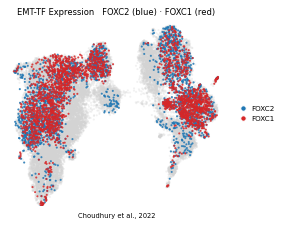

In [5]:
# deliverable: expression.pdf - categorical overlay of thresholded expressers on a grey
# manifold (reference style: NOT a continuous colormap). threshold = top decile among
# expressing cells per factor, so a broadly-expressed TF is not washed across the manifold.
xy = adata.obsm['X_umap']
xlo, xhi = np.percentile(xy[:, 0], [0.3, 99.7]); ylo, yhi = np.percentile(xy[:, 1], [0.3, 99.7])
px = (xhi-xlo)*.05; py = (yhi-ylo)*.05
def _vec(g):
    x = adata[:, g].X
    return x.toarray().ravel() if hasattr(x, 'toarray') else np.asarray(x).ravel()
thr = {}
for g in sel:
    v = _vec(g); pos = v[v > 0]; thr[g] = float(np.quantile(pos, 0.90)) if pos.size else 0.0
seln = {g: _vec(g) > thr[g] for g in sel}
print('overlay thresholds (top decile among expressers):', {g: round(thr[g], 2) for g in thr},
      '| cells shown:', {g: int(seln[g].sum()) for g in seln})
order = sorted(sel, key=lambda g: -int(seln[g].sum()))
colors = {sel[0]: 'tab:blue', sel[1]: 'tab:red'}
fig, ax = plt.subplots(figsize=(3.5, 3.0))
sc.pl.umap(adata, size=14, alpha=.3, frameon=False, show=False, ax=ax, na_color='lightgray')
for g in order:
    ap = adata[seln[g]].copy()
    sc.pl.umap(ap, na_color=colors[g], size=14, alpha=.85, frameon=False, show=False, ax=ax)
ax.set_xlim(xlo-px, xhi+px); ax.set_ylim(ylo-py, yhi+py)
from matplotlib.lines import Line2D
ax.legend(handles=[Line2D([0],[0],marker='o',color='w',markerfacecolor=colors[g],markersize=5,label=g) for g in sel],
          loc='center left', bbox_to_anchor=(1.02,.5), frameon=False, fontsize=6.5, handletextpad=.2)
ax.set_title(f'EMT-TF Expression   {sel[0]} (blue) \u00b7 {sel[1]} (red)', size=7.5)
ax.text(.5, -.06, 'Choudhury et al., 2022', ha='center', transform=ax.transAxes, size=6)
fig.savefig(os.path.join(pth_fig, 'expression.pdf'), bbox_inches='tight')
for g in sel:
    print(f'{g}: {(_vec(g)>0).mean()*100:.1f}% expressing; {int(seln[g].sum())} shown (top decile)')
print('saved expression.pdf')